In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [2]:
X, y_true = make_blobs(n_samples=500, centers=3, cluster_std=0.60, random_state=42)

In [3]:
df = pd.DataFrame(X, columns=['Feature_1', 'Feature_2'])

In [4]:
df

,Feature_1,Feature_2
0,-6.190063,-7.302015
1,3.021747,1.940593
2,5.953761,1.488191
3,-2.744463,8.136177
4,5.360607,1.728324
...,...,...
495,-6.040014,-6.325329
496,-2.555459,9.218977
497,4.438408,2.974583
498,-7.193261,-6.250704


In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

In [6]:
inertia = []
K_range = range(1,11)

In [7]:
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

In [8]:
inertia

[1000.0000000000002,
 297.8954141051722,
 11.575484723104978,
 9.752067977356838,
 8.25717527244628,
 6.9175773204167985,
 6.334755391595288,
 5.70417717790143,
 5.0602341335320755,
 4.762361898130396]

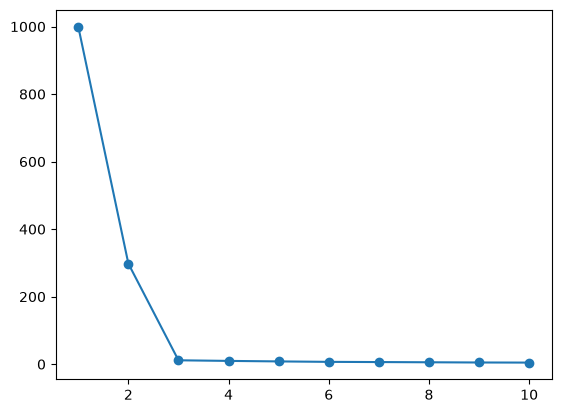

In [9]:
plt.plot(K_range, inertia, marker=
         'o')

In [10]:
kmeans_final = KMeans(n_clusters=3, random_state=42)

In [11]:
cluester_labels = kmeans_final.fit_predict(X_scaled)

In [12]:
cluester_labels

array([1, 0, 0, 2, 0, 0, 1, 0, 0, 1, 0, 2, 2, 2, 0, 0, 2, 1, 1, 2, 0, 2,
       0, 1, 1, 0, 0, 1, 1, 2, 0, 2, 2, 2, 0, 0, 0, 0, 1, 1, 0, 2, 2, 2,
       2, 0, 0, 0, 0, 1, 1, 2, 1, 1, 0, 2, 2, 1, 0, 1, 1, 2, 0, 1, 0, 1,
       0, 1, 2, 0, 0, 0, 0, 1, 2, 1, 2, 0, 2, 2, 1, 2, 0, 2, 1, 1, 1, 1,
       0, 2, 1, 0, 2, 0, 0, 1, 2, 2, 2, 1, 0, 2, 2, 1, 1, 2, 2, 1, 2, 1,
       1, 1, 1, 1, 1, 0, 2, 1, 0, 1, 2, 2, 0, 0, 1, 0, 2, 0, 1, 1, 1, 0,
       0, 1, 0, 1, 1, 1, 0, 2, 1, 1, 0, 0, 1, 1, 1, 2, 2, 2, 0, 1, 0, 0,
       2, 1, 2, 1, 0, 0, 1, 1, 2, 2, 1, 2, 2, 0, 1, 1, 1, 2, 2, 1, 1, 2,
       2, 0, 0, 0, 2, 1, 2, 2, 1, 1, 2, 0, 2, 1, 1, 1, 1, 1, 2, 0, 2, 2,
       1, 0, 2, 2, 1, 1, 0, 1, 0, 2, 2, 1, 1, 0, 1, 2, 2, 1, 2, 1, 2, 0,
       0, 2, 1, 2, 0, 2, 2, 1, 0, 0, 0, 0, 2, 1, 1, 1, 2, 0, 2, 0, 0, 0,
       2, 2, 1, 1, 0, 2, 2, 0, 2, 2, 2, 2, 0, 2, 1, 2, 1, 2, 2, 2, 1, 2,
       0, 0, 0, 2, 0, 0, 2, 2, 0, 1, 2, 2, 2, 2, 1, 1, 2, 0, 2, 2, 1, 2,
       0, 1, 0, 0, 1, 2, 2, 2, 1, 2, 1, 0, 0, 2, 0,

In [13]:
df['cluster'] = cluester_labels

<Axes: xlabel='Feature_1', ylabel='Feature_2'>

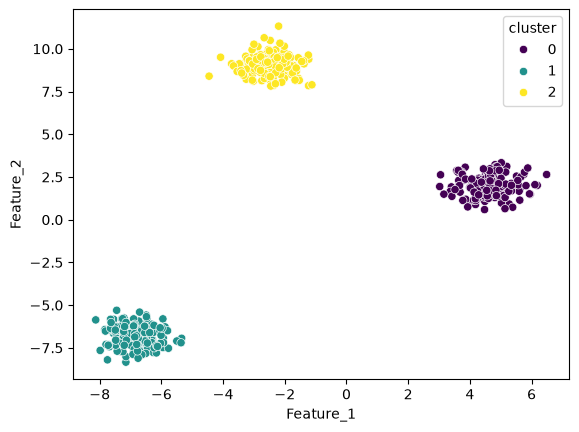

In [14]:
sns.scatterplot(x=df['Feature_1'],
                y = df['Feature_2'],
                hue= df['cluster'],
                palette='viridis')

In [16]:
from sklearn.datasets import make_moons

In [17]:
X, y_true = make_moons(n_samples=500, noise=0.05, random_state=42)

In [18]:
from sklearn.cluster import KMeans, DBSCAN

In [19]:
df = pd.DataFrame(X, columns=['Features1', 'Features2'])

In [20]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

In [21]:
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

In [25]:
df['kmeans_cluster'] = kmeans_labels

<Axes: xlabel='Features1', ylabel='Features2'>

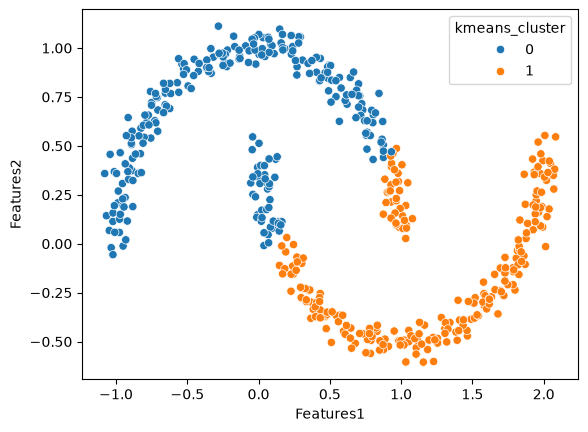

In [26]:
import seaborn as sns
sns.scatterplot(
    x=df['Features1'],
    y=df['Features2'], 
    hue=df['kmeans_cluster'],
    palette='tab10'
)

In [27]:
dbscan = DBSCAN(eps=0.3, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

In [28]:
df['dbscan_cluster'] = dbscan_labels

<Axes: xlabel='Features1', ylabel='Features2'>

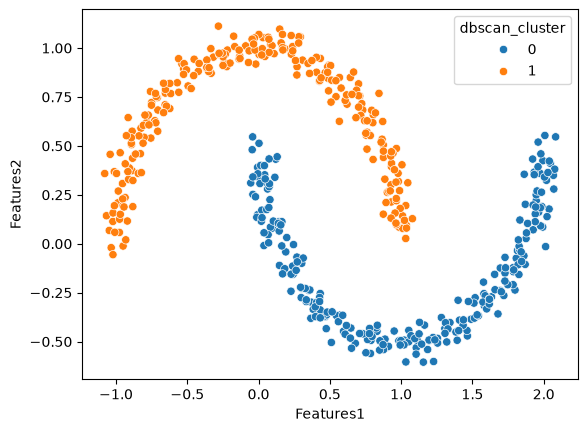

In [29]:
sns.scatterplot(
    x=df['Features1'],
    y=df['Features2'],
    hue = df['dbscan_cluster'], 
    palette='tab10'
)